## **Loading the data**

In [1]:
import pandas as pd
import geopandas as gpd
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

cube = gpd.read_file(
    "H3Polygon4ISC.gpkg",
    engine="pyogrio",
    use_arrow=True,
) 

## **Visualizing the covariates and checking the sanity of the data**

Target cells displayed on each map: 425


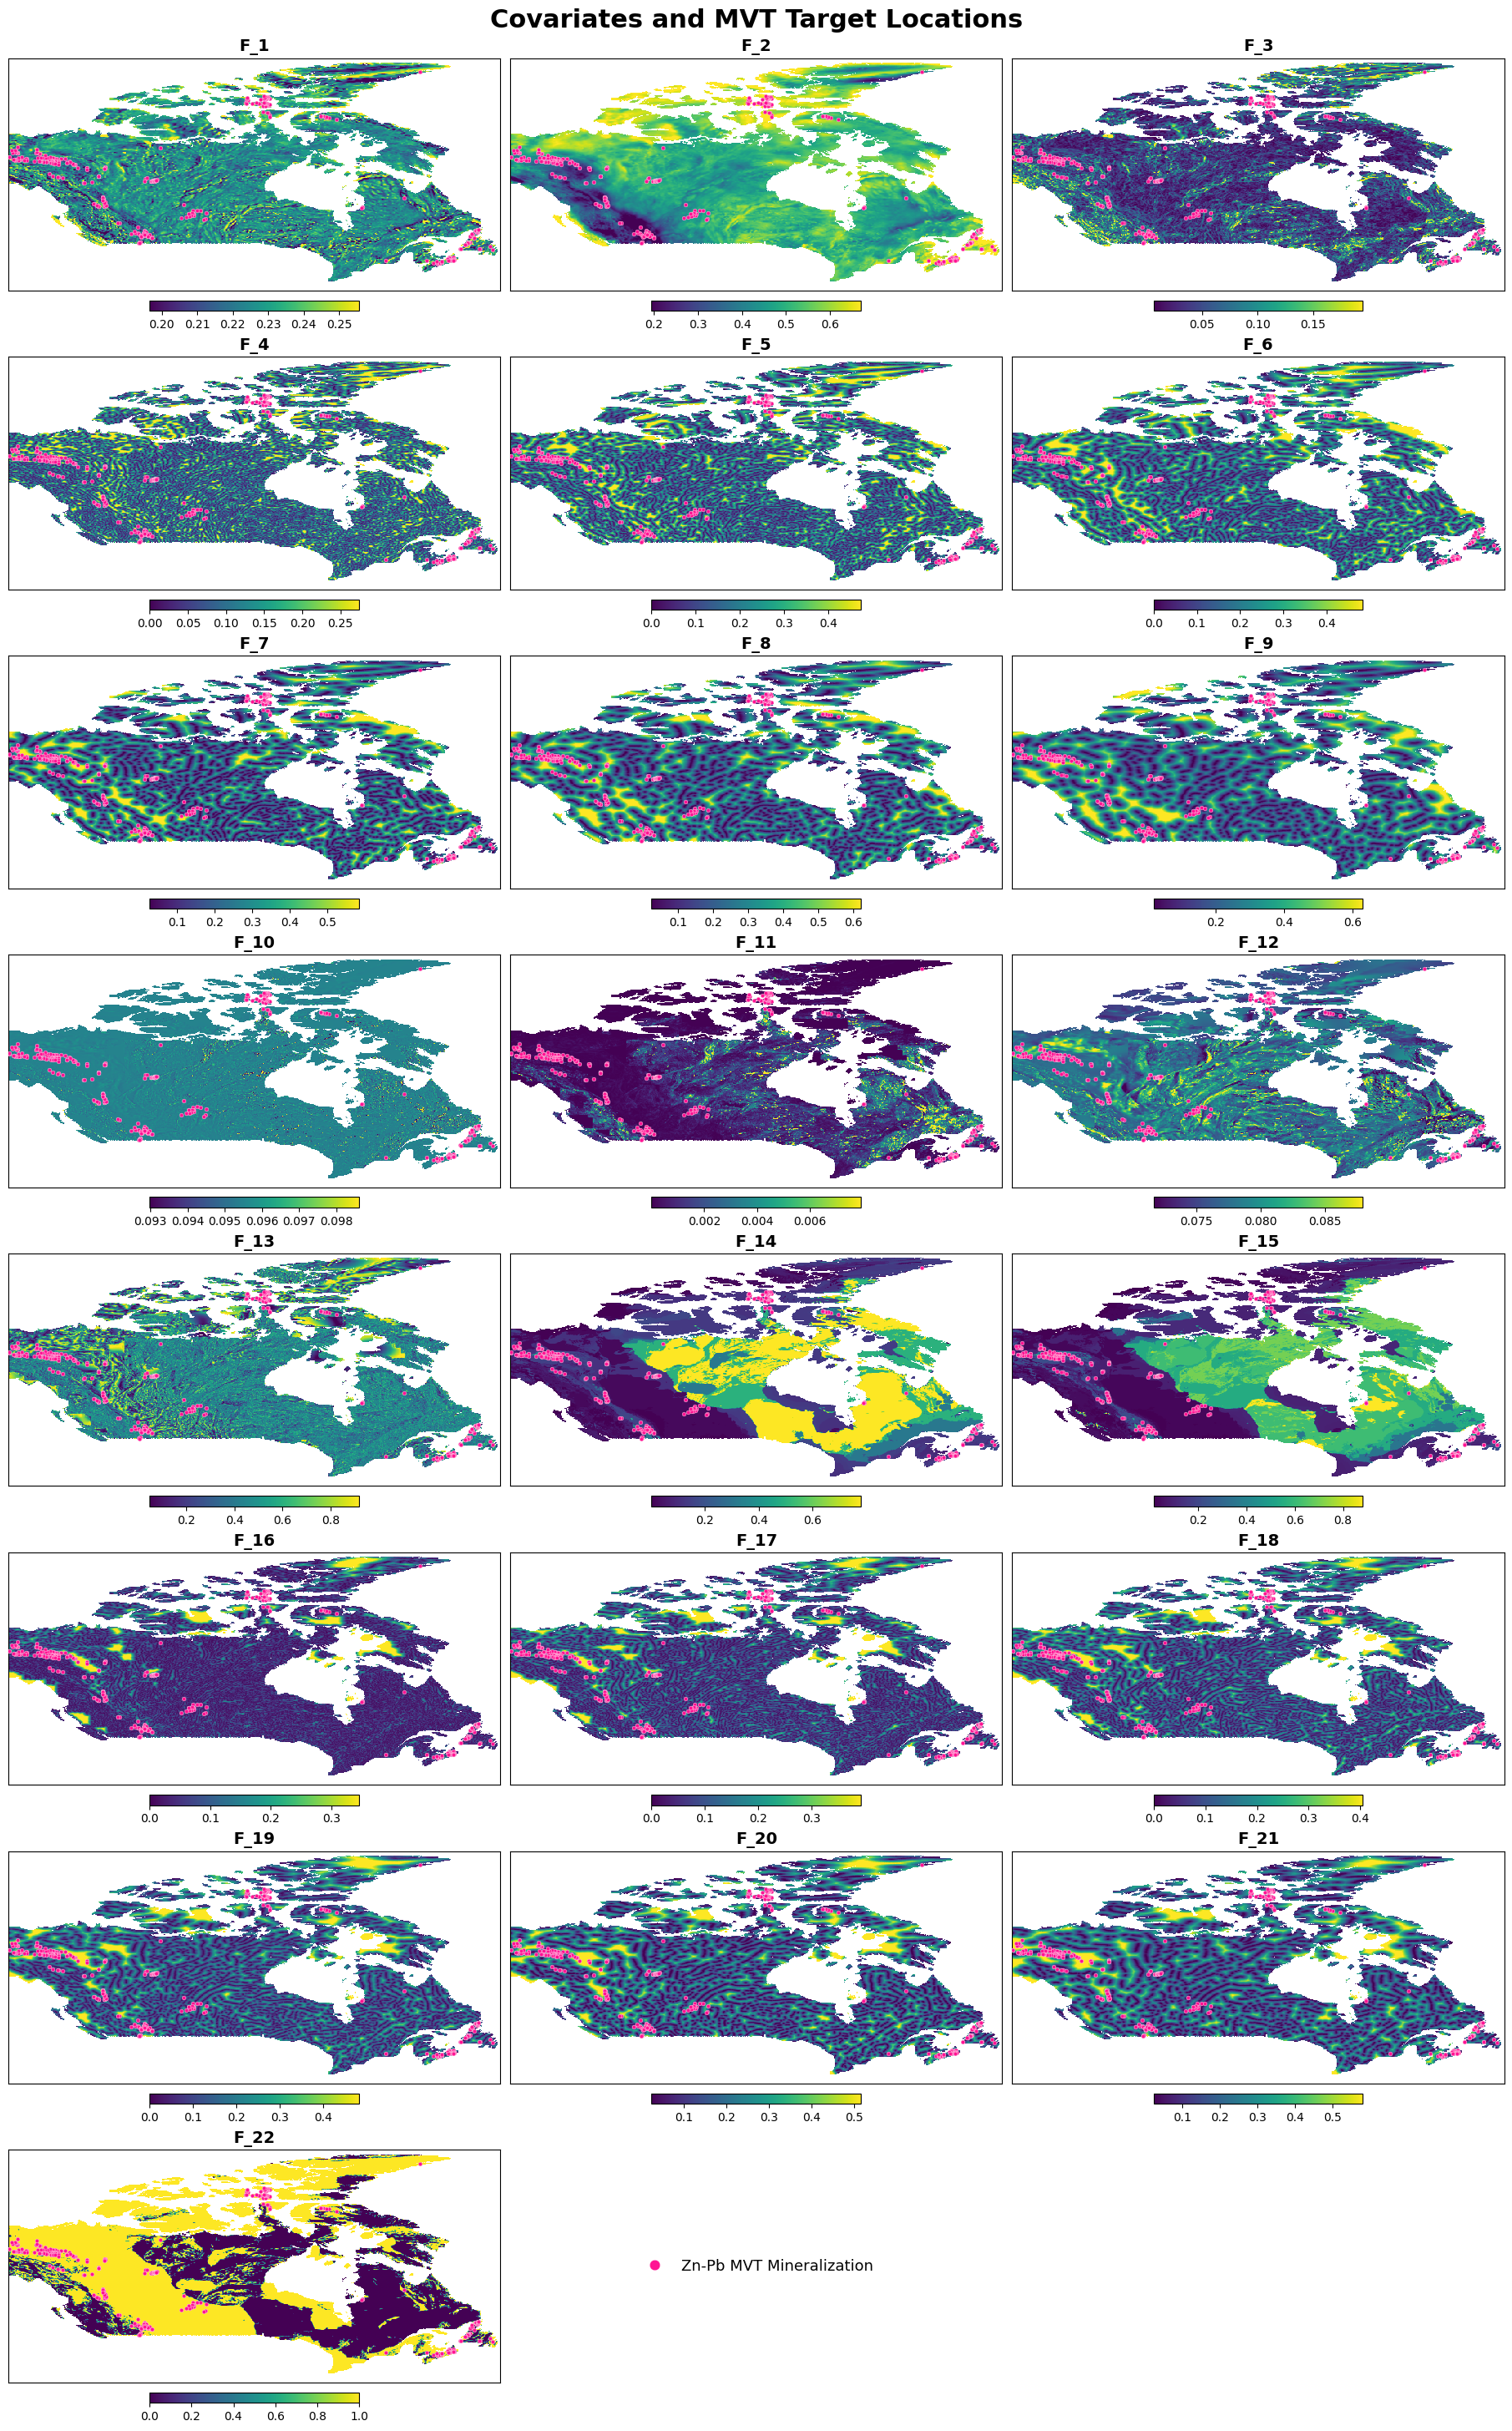

In [2]:
# ============================================================
# Overview of covariates with MVT target locations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Settings
# ============================================================

FEATURES = [f"F_{i}" for i in range(1, 23)]

NX, NY = 700, 450
EXTENT = (-141, -52, 40, 84)

N_COLS = 3
N_ROWS = (len(FEATURES) + N_COLS - 1) // N_COLS

FIGSIZE = (18, 29)
CMAP = "viridis"

TARGET_COLOR = "#FF1493"
TARGET_SIZE = 12
TARGET_EDGE_COLOR = "white"
TARGET_EDGE_WIDTH = 0.25
TARGET_LABEL = "Zn-Pb MVT Mineralization"


# ============================================================
# 2. Validate columns and prepare coordinates
# ============================================================

required = ["longitude", "latitude", "target"] + FEATURES
missing = [column for column in required if column not in cube.columns]

if missing:
    raise KeyError(f"Missing columns: {missing}")

lon = pd.to_numeric(
    cube["longitude"], errors="coerce"
).to_numpy(dtype=float)

lat = pd.to_numeric(
    cube["latitude"], errors="coerce"
).to_numpy(dtype=float)

target = pd.to_numeric(
    cube["target"], errors="coerce"
).to_numpy(dtype=float)

xmin, xmax, ymin, ymax = EXTENT

valid_coordinates = (
    np.isfinite(lon)
    & np.isfinite(lat)
    & (lon >= xmin)
    & (lon <= xmax)
    & (lat >= ymin)
    & (lat <= ymax)
)

rows = np.flatnonzero(valid_coordinates)

if rows.size == 0:
    raise ValueError("No valid coordinates within the map extent.")

target_mask = valid_coordinates & (target == 1)
target_lon = lon[target_mask]
target_lat = lat[target_mask]

print(f"Target cells displayed on each map: {target_mask.sum():,}")


# ============================================================
# 3. Compute display-pixel positions once
# ============================================================

ix = np.clip(
    ((lon[rows] - xmin) / (xmax - xmin) * NX).astype(int),
    0,
    NX - 1,
)

iy = np.clip(
    ((lat[rows] - ymin) / (ymax - ymin) * NY).astype(int),
    0,
    NY - 1,
)

pixel_ids = iy * NX + ix


# ============================================================
# 4. Plot covariates and overlay target locations
# ============================================================

fig, axes = plt.subplots(
    N_ROWS,
    N_COLS,
    figsize=FIGSIZE,
    layout="constrained",
    squeeze=False,
)

for ax, feature in zip(axes.flat, FEATURES):

    values = pd.to_numeric(
        cube[feature], errors="coerce"
    ).to_numpy(dtype=float)[rows]

    finite = np.isfinite(values)

    ax.set_title(feature, fontsize=14, fontweight="bold")

    if finite.any():

        sums = np.bincount(
            pixel_ids[finite],
            weights=values[finite],
            minlength=NX * NY,
        )

        counts = np.bincount(
            pixel_ids[finite],
            minlength=NX * NY,
        )

        grid = np.full(NX * NY, np.nan)

        np.divide(
            sums,
            counts,
            out=grid,
            where=counts > 0,
        )

        grid = grid.reshape(NY, NX)

        
        vmin, vmax = np.percentile(values[finite], [2, 98])

        if vmin == vmax:
            vmin = values[finite].min()
            vmax = values[finite].max()

        
        if vmin == vmax:
            padding = max(abs(vmin) * 0.01, 0.01)
            vmin -= padding
            vmax += padding

        image = ax.imshow(
            np.ma.masked_invalid(grid),
            origin="lower",
            extent=EXTENT,
            cmap=CMAP,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            aspect="auto",
            zorder=1,
        )

        colorbar = fig.colorbar(
            image,
            ax=ax,
            orientation="horizontal",
            fraction=0.045,
            pad=0.04,
        )

        colorbar.ax.tick_params(labelsize=10)

    else:
        ax.text(
            0.5,
            0.5,
            "No valid feature data",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=12,
        )

    
    ax.scatter(
        target_lon,
        target_lat,
        s=TARGET_SIZE,
        marker="o",
        facecolors=TARGET_COLOR,
        edgecolors=TARGET_EDGE_COLOR,
        linewidths=TARGET_EDGE_WIDTH,
        zorder=3,
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])


# ============================================================
# 5. Shared legend in an unused panel
# ============================================================

unused_axes = list(axes.flat)[len(FEATURES):]

for ax in unused_axes:
    ax.set_axis_off()

target_handle = Line2D(
    [],
    [],
    linestyle="none",
    marker="o",
    markerfacecolor=TARGET_COLOR,
    markeredgecolor=TARGET_EDGE_COLOR,
    markeredgewidth=TARGET_EDGE_WIDTH,
    markersize=9,
    label=TARGET_LABEL,
)

if unused_axes:
    unused_axes[0].legend(
        handles=[target_handle],
        loc="center",
        fontsize=13,
        frameon=False,
    )

fig.suptitle(
    "Covariates and MVT Target Locations",
    fontsize=22,
    fontweight="bold",
)

plt.show()

## **Spatial Distribution of Labels with respect to Canada's Geological Provinces**

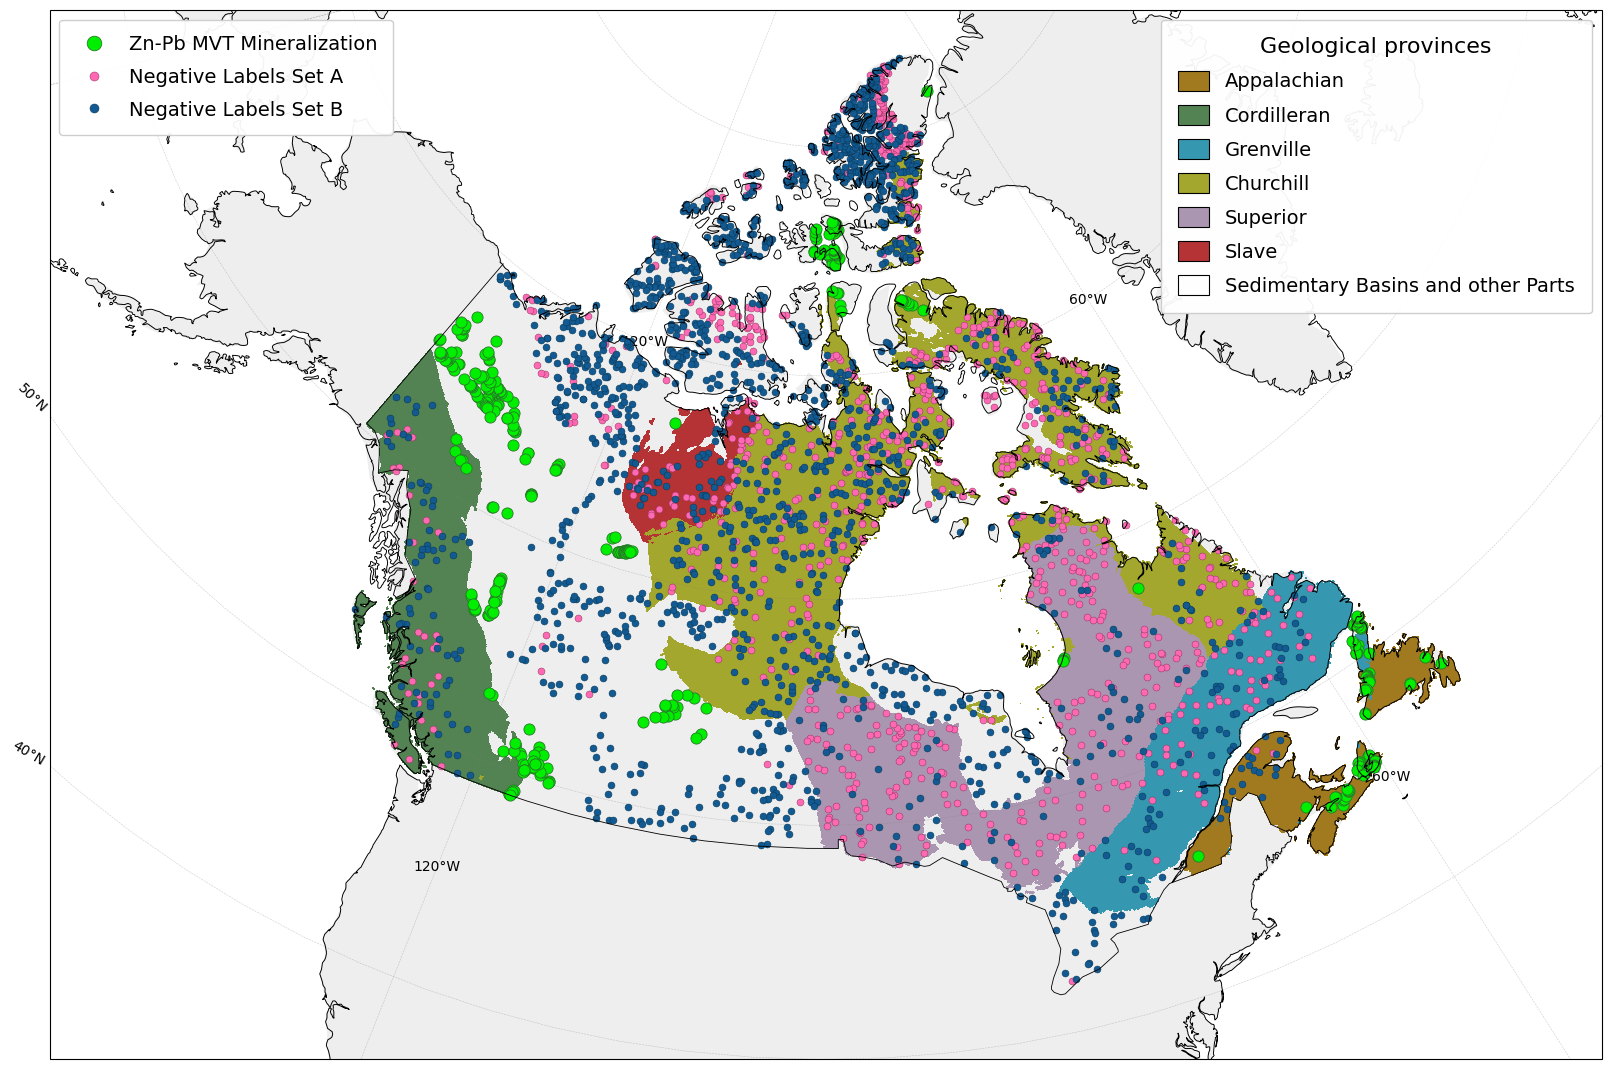

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba

import cartopy.crs as ccrs
import cartopy.feature as cfeature


# ============================================================
# 1. Validate columns and coordinates
# ============================================================

cols = {str(c).strip().lower(): c for c in cube.columns}

required = [
    "longitude", "latitude", "gprovince",
    "seta", "setb", "target",
]

missing = [name for name in required if name not in cols]

if missing:
    raise KeyError(f"Required columns are missing: {missing}")

lon = pd.to_numeric(cube[cols["longitude"]], errors="coerce")
lat = pd.to_numeric(cube[cols["latitude"]], errors="coerce")

valid = lon.between(-180, 180) & lat.between(-90, 90)


# ============================================================
# 2. Geological-province colours
# ============================================================

province = (
    cube[cols["gprovince"]]
    .astype("string")
    .str.strip()
    .str.casefold()
    .replace({
        "": pd.NA,
        "appalachian": "Appalachian",
        "appalachians": "Appalachian",
        "cordillera": "Cordilleran",
        "cordilleran": "Cordilleran",
        "grenville": "Grenville",
        "churchill": "Churchill",
        "superior": "Superior",
        "slave": "Slave",
        "wcsb": "WCSB",
    })
)

province_colors = {
    "Appalachian": "#A17A20",
    "Cordilleran": "#538352",
    "Grenville": "#3698B0",
    "Churchill": "#A4A72D",
    "Superior": "#AA96B0",
    "Slave": "#B63335",
    "WCSB": "#00000000",
}

unknown = sorted(set(province.dropna()) - set(province_colors))

if unknown:
    raise ValueError(f"Add colours for these province names: {unknown}")

province_names = [
    name for name in province_colors
    if province.eq(name).any()
]


# ============================================================
# 3. Sample-symbol settings
# ============================================================


NEGATIVE_SIZE = 25
TARGET_SIZE = 65

layers = [
    {
        "column": "SetA",
        "label": "Negative Labels Set A",
        "color": "#FF69B4",       # Pink
        "size": NEGATIVE_SIZE,
        "edge": "#91335F",
        "edge_width": 0.35,
    },
    {
        "column": "SetB",
        "label": "Negative Labels Set B",
        "color": "#125A91",       # Blue
        "size": NEGATIVE_SIZE,
        "edge": "#083653",
        "edge_width": 0.35,
    },
    {
        "column": "target",
        "label": "Zn-Pb MVT Mineralization",
        "color": "#00EE00",
        "size": TARGET_SIZE,
        "edge": "#277A27",
        "edge_width": 0.6,
    },
]


# ============================================================
# 4. Create map
# ============================================================

projection = ccrs.LambertConformal(
    central_longitude=-96,
    central_latitude=60,
    standard_parallels=(49, 77),
)

fig, ax = plt.subplots(
    figsize=(16, 13),
    subplot_kw={"projection": projection},
    constrained_layout=True,
)

ax.set_extent(
    [-142, -50, 40, 84],
    crs=ccrs.PlateCarree(),
)

ax.set_facecolor("white")
ax.add_feature(
    cfeature.LAND,
    facecolor="#EEEEEE",
    zorder=0,
)


# ============================================================
# 5. Geological-province background
# ============================================================

background = valid & province.notna()

if background.any():
    codes = pd.Categorical(
        province.loc[background],
        categories=province_names,
    ).codes

    palette = np.asarray([
        to_rgba(province_colors[name])
        for name in province_names
    ])

    ax.scatter(
        lon.loc[background].to_numpy(),
        lat.loc[background].to_numpy(),
        c=palette[codes],
        s=1,
        marker="s",
        linewidths=0,
        rasterized=True,
        transform=ccrs.PlateCarree(),
        zorder=1,
    )


# ============================================================
# 6. Negative labels and targets — all circular symbols
# ============================================================

sample_handles = {}

for layer in layers:
    column = layer["column"]

    values = pd.to_numeric(
        cube[cols[column.lower()]],
        errors="coerce",
    )

    selected = values.eq(1) & valid

    ax.scatter(
        lon.loc[selected],
        lat.loc[selected],
        s=layer["size"],
        marker="o",
        facecolors=layer["color"],
        edgecolors=layer["edge"],
        linewidths=layer["edge_width"],
        rasterized=True,
        transform=ccrs.PlateCarree(),
        zorder=4 if column == "target" else 3,
    )

    
    sample_handles[column] = Line2D(
        [], [],
        linestyle="none",
        marker="o",
        markerfacecolor=layer["color"],
        markeredgecolor=layer["edge"],
        markeredgewidth=layer["edge_width"],
        markersize=np.sqrt(layer["size"]),
        label=layer["label"],
    )

ax.coastlines(
    resolution="50m",
    linewidth=0.7,
    zorder=5,
)

ax.add_feature(
    cfeature.BORDERS,
    linewidth=0.6,
    zorder=5,
)

grid = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    color="gray",
    alpha=0.4,
    linestyle="--",
)

grid.top_labels = False
grid.right_labels = False


# ============================================================
# 7. Sample legend
# ============================================================

sample_legend = ax.legend(
    handles=[
        sample_handles["target"],
        sample_handles["SetA"],
        sample_handles["SetB"],
    ],
    loc="upper left",
    fontsize=14,
    markerscale=1.3,
    framealpha=0.95,
    labelspacing=0.7,
    borderpad=0.8,
)

ax.add_artist(sample_legend)


# ============================================================
# 8. Geological-province legend
# ============================================================

province_handles = [
    Patch(
        facecolor=province_colors[name],
        edgecolor="black",
        linewidth=0.8,
        label=name,
    )
    for name in province_names
    if name != "WCSB"
]

province_handles.append(
    Patch(
        facecolor="none",
        edgecolor="black",
        linewidth=0.8,
        label="Sedimentary Basins and other Parts",
    )
)

ax.legend(
    handles=province_handles,
    title="Geological provinces",
    loc="upper right",
    fontsize=14,
    title_fontsize=16,
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    handlelength=1.6,
    handleheight=1.2,
    labelspacing=0.7,
    borderpad=0.9,
)


# ============================================================
# 9. Save and display
# ============================================================

fig.savefig(
    "1_Label Distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

## **Modelling (Training and 5-Fold Cross Validation)**

In [10]:
import gc
from pathlib import Path

import h3
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import auc, roc_auc_score


# ============================================================
# Step 1. Target columns and general setting
# ============================================================

TARGET_COL = "target"
NEGATIVE_COLS = ["SetA", "SetB"]
FEATURE_COLS = [f"F_{i}" for i in range(1, 23)]

STRATEGIES = {
    "SetA": {
        "name": "Set A",
        "color": "tab:blue",
        "score_col": "prospectivity_model_A",
    },
    "SetB": {
        "name": "Set B",
        "color": "tab:orange",
        "score_col": "prospectivity_model_B",
    },
}


H3_COL = None
H3_RESOLUTION = 7
LAT_COL = "latitude"
LON_COL = "longitude"

N_MODELS = 10
N_SPLITS = 5
RANDOM_STATE = 42
PREDICTION_BATCH_SIZE = 100_000

ALPHA_VALUES = np.linspace(0.0, 2.5, 50)
PLOT_GRID = np.linspace(0.0, 1.0, 2001)

SAVE_FOLD_MAPS = True
FIT_FINAL_MODELS = True

OUTPUT_DIR = Path("ModelingResults")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# Step 2. Sanity checking
# ============================================================

if N_MODELS < 1:
    raise ValueError("N_MODELS must be at least 1.")

if N_SPLITS < 2:
    raise ValueError("N_SPLITS must be at least 2.")

if PREDICTION_BATCH_SIZE < 1:
    raise ValueError("PREDICTION_BATCH_SIZE must be positive.")

work = cube.copy().reset_index(drop=True)

if work.empty:
    raise ValueError("cube is empty.")

if work.columns.duplicated().any():
    raise ValueError("Duplicate column names found.")


def resolve_column(requested):
    matches = [
        col for col in work.columns
        if str(col).strip().casefold() == requested.strip().casefold()
    ]

    if len(matches) != 1:
        raise KeyError(
            f"Expected one column matching {requested!r}; "
            f"found {matches}."
        )

    return matches[0]


for canonical in [TARGET_COL, *NEGATIVE_COLS]:
    source = resolve_column(canonical)
    values = pd.to_numeric(work[source], errors="coerce")

    if values.isna().any() or not values.isin([0, 1]).all():
        raise ValueError(
            f"{source} must contain only 0 and 1 without missing values."
        )

    work[canonical] = values.astype(np.uint8)

target_mask = work[TARGET_COL].eq(1).to_numpy()

for neg_col in NEGATIVE_COLS:
    overlap = target_mask & work[neg_col].eq(1).to_numpy()

    if overlap.any():
        print(
            f"Removing {overlap.sum():,} positive cells "
            f"from {neg_col}; target labels retained."
        )
        work.loc[overlap, neg_col] = 0

feature_sources = [
    resolve_column(col)
    for col in FEATURE_COLS
]

X_all = (
    work[feature_sources]
    .apply(pd.to_numeric, errors="coerce")
    .to_numpy(dtype=np.float32)
)

valid_columns = np.isfinite(X_all).all(axis=0)

if not valid_columns.all():
    bad_columns = [
        feature_sources[j]
        for j in np.flatnonzero(~valid_columns)
    ]

    raise ValueError(
        f"Missing or nonfinite predictors: {bad_columns}. "
        "Resolve these before modelling."
    )


# ============================================================
# Step 3. Prerequirement for success rate curves
# ============================================================

if hasattr(h3, "latlng_to_cell"):
    latlng_to_cell = h3.latlng_to_cell
    is_valid_cell = h3.is_valid_cell
    get_resolution = h3.get_resolution
else:
    latlng_to_cell = h3.geo_to_h3
    is_valid_cell = h3.h3_is_valid
    get_resolution = h3.h3_get_resolution


def normalize_h3(value):
    if pd.isna(value):
        raise ValueError("Missing H3 ID.")

    if isinstance(value, (int, np.integer)):
        return format(int(value), "x")

    if isinstance(value, str):
        return value.strip().lower()

    raise ValueError(
        "H3 IDs must be strings or integers, not floating-point values."
    )


effective_h3_col = None

if H3_COL is not None:
    effective_h3_col = resolve_column(H3_COL)

else:
    for candidate in ["H3id", "evaluation_h3_index"]:
        matches = [
            col for col in work.columns
            if str(col).strip().casefold() == candidate.casefold()
        ]

        if len(matches) > 1:
            raise ValueError(f"Ambiguous H3 columns: {matches}")

        if matches:
            effective_h3_col = matches[0]
            break

if effective_h3_col is not None:
    print(f"Using H3 IDs from: {effective_h3_col}")

    cell_ids = np.array([
        normalize_h3(value)
        for value in work[effective_h3_col]
    ])

else:
    lat = pd.to_numeric(
        work[resolve_column(LAT_COL)],
        errors="coerce",
    )

    lon = pd.to_numeric(
        work[resolve_column(LON_COL)],
        errors="coerce",
    )

    if not (
        lat.between(-90, 90)
        & lon.between(-180, 180)
    ).all():
        raise ValueError("Invalid latitude/longitude.")

    print("Reconstructing H3 IDs from cell-centre coordinates...")

    cell_ids = np.array([
        latlng_to_cell(float(la), float(lo), H3_RESOLUTION)
        for la, lo in zip(lat, lon)
    ])

if not all(is_valid_cell(cell) for cell in cell_ids):
    raise ValueError("Invalid H3 IDs found.")

if not all(
    get_resolution(cell) == H3_RESOLUTION
    for cell in cell_ids
):
    raise ValueError(
        f"All cells must have H3 resolution {H3_RESOLUTION}."
    )

if pd.Index(cell_ids).has_duplicates:
    raise ValueError("Expected one row per H3 cell.")

work["evaluation_h3_index"] = cell_ids

print(f"\nStudy-area cells: {len(work):,}")
print(f"Positive cells: {target_mask.sum():,}")
print(f"Predictors: {len(FEATURE_COLS)}")
print("Coverage: selected H3 cells / all H3 cells")


# ============================================================
# Step 4. 5-fold Cross Validation
# ============================================================

positive_rows = np.flatnonzero(target_mask)

if len(positive_rows) < N_SPLITS:
    raise ValueError("Too few positive cells for the requested folds.")

# Both strategies use identical held-out positive groups.
positive_folds = np.array_split(
    np.random.default_rng(
        RANDOM_STATE
    ).permutation(positive_rows),
    N_SPLITS,
)

strategy_data = {}

for strategy_id, neg_col in enumerate(NEGATIVE_COLS, start=1):
    negative_mask = work[neg_col].eq(1).to_numpy()
    negative_rows = np.flatnonzero(negative_mask)

    if len(negative_rows) < max(N_SPLITS, len(positive_rows)):
        raise ValueError(
            f"{neg_col}: insufficient negative cells "
            "for balanced training and CV."
        )

    negative_folds = np.array_split(
        np.random.default_rng(
            RANDOM_STATE + strategy_id * 1000
        ).permutation(negative_rows),
        N_SPLITS,
    )

    for fold_id in range(N_SPLITS):
        n_train_pos = (
            len(positive_rows) - len(positive_folds[fold_id])
        )
        n_train_neg = (
            len(negative_rows) - len(negative_folds[fold_id])
        )

        if n_train_neg < n_train_pos:
            raise ValueError(
                f"{neg_col}, fold {fold_id + 1}: "
                "insufficient training negatives."
            )

    strategy_data[neg_col] = {
        "negative_mask": negative_mask,
        "negative_folds": negative_folds,
    }

    print(f"{neg_col}: {len(negative_rows):,} eligible negatives")


# ============================================================
# Step 5. Algorithm (Random Forest Ensemble) Preparation
# ============================================================


param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
    "bootstrap": [True],
    "class_weight": [None],
}

param_list = list(
    ParameterSampler(
        param_dist,
        n_iter=N_MODELS,
        random_state=RANDOM_STATE,
    )
)


# ============================================================
# Step 6. Balanced ensemble and full-grid prediction
# ============================================================

def fit_predict_full_grid(training_rows, training_labels, seed):
    training_rows = np.asarray(training_rows, dtype=int)
    training_labels = np.asarray(
        training_labels,
        dtype=np.uint8,
    )

    pos = training_rows[training_labels == 1]
    neg = training_rows[training_labels == 0]

    if len(pos) == 0 or len(neg) < len(pos):
        raise ValueError(
            f"Cannot balance {len(pos):,} positives "
            f"and {len(neg):,} negatives."
        )

    rng = np.random.default_rng(seed)
    mean_scores = np.zeros(len(X_all), dtype=np.float64)

    for member_id, params in enumerate(param_list):
        sampled_rows = np.concatenate([
            rng.choice(pos, size=len(pos), replace=True),
            rng.choice(neg, size=len(pos), replace=False),
        ])

        sampled_labels = np.concatenate([
            np.ones(len(pos), dtype=np.uint8),
            np.zeros(len(pos), dtype=np.uint8),
        ])

        shuffled = rng.permutation(len(sampled_rows))

        model = RandomForestClassifier(
            **params,
            random_state=seed + member_id + 1,
            n_jobs=-1,
        )

        model.fit(
            X_all[sampled_rows[shuffled]],
            sampled_labels[shuffled],
        )

        positive_column = int(
            np.flatnonzero(model.classes_ == 1)[0]
        )

        for start in range(
            0, len(X_all), PREDICTION_BATCH_SIZE
        ):
            stop = min(
                start + PREDICTION_BATCH_SIZE,
                len(X_all),
            )

            mean_scores[start:stop] += (
                model.predict_proba(
                    X_all[start:stop]
                )[:, positive_column]
                / len(param_list)
            )

        print(
            f"  Completed member "
            f"{member_id + 1}/{len(param_list)}"
        )

        del model
        gc.collect()

    return mean_scores


# ============================================================
# Step 7. Evaluate using cell-count coverage
# ============================================================

def evaluate_full_map(scores, evaluation_pos, evaluation_neg):
    """
    Coverage:
        Selected cells / all cells in cube.

    TPR:
        Selected held-out positives / all held-out positives.

    FPR:
        Selected held-out negatives / all held-out negatives.

    All quantities use identical score thresholds.
    Equal scores enter together.
    """

    scores = np.asarray(scores, dtype=float)
    evaluation_pos = np.asarray(evaluation_pos, dtype=bool)
    evaluation_neg = np.asarray(evaluation_neg, dtype=bool)

    if not (
        len(scores)
        == len(evaluation_pos)
        == len(evaluation_neg)
        == len(work)
    ):
        raise ValueError("Prediction and evaluation lengths differ.")

    if not np.isfinite(scores).all():
        raise ValueError("Nonfinite prediction scores.")

    if (evaluation_pos & evaluation_neg).any():
        raise ValueError("Positive and negative evaluation masks overlap.")

    n_pos = int(evaluation_pos.sum())
    n_neg = int(evaluation_neg.sum())

    if n_pos == 0 or n_neg == 0:
        raise ValueError("Both evaluation classes are required.")

    order = np.argsort(-scores, kind="stable")
    sorted_scores = scores[order]

    # Indices of the final cell in each tied-score group.
    group_end_indices = np.flatnonzero(
        np.r_[
            sorted_scores[:-1] != sorted_scores[1:],
            True,
        ]
    )

    coverage = np.r_[
        0.0,
        (group_end_indices + 1) / len(scores),
    ]

    tpr = np.r_[
        0.0,
        np.cumsum(evaluation_pos[order])[group_end_indices] / n_pos,
    ]

    fpr = np.r_[
        0.0,
        np.cumsum(evaluation_neg[order])[group_end_indices] / n_neg,
    ]

    # AUCs use original threshold paths.
    sr_auc = float(auc(coverage, tpr))
    roc_auc = float(auc(fpr, tpr))

    # ISC cost = (coverage + alpha * FPR) / (1 + alpha).
    isc_auc_values = (
        sr_auc + ALPHA_VALUES * roc_auc
    ) / (1.0 + ALPHA_VALUES)

    isc_alpha_plots = np.stack([
        np.interp(
            PLOT_GRID,
            (coverage + alpha * fpr) / (1.0 + alpha),
            tpr,
        )
        for alpha in ALPHA_VALUES
    ])

    return {
        "n_positive": n_pos,
        "n_negative": n_neg,
        "ROC_AUC": roc_auc,
        "SR_AUC": sr_auc,
        "ISC_AUC_values": isc_auc_values,
        "ISC_AUC_alpha_mean": float(isc_auc_values.mean()),
        "roc_plot": np.interp(PLOT_GRID, fpr, tpr),
        "sr_plot": np.interp(PLOT_GRID, coverage, tpr),
        "isc_alpha_plots": isc_alpha_plots,
        "isc_mean_plot": isc_alpha_plots.mean(axis=0),
    }


def metric_record(neg_col, result, evaluation, fold=None):
    values = result["ISC_AUC_values"]

    return {
        "negative_class": neg_col,
        "evaluation": evaluation,
        "fold": fold,
        "coverage_method": "cell_count",
        "n_study_cells": len(work),
        "n_positive": result["n_positive"],
        "n_negative": result["n_negative"],
        "ROC_AUC": float(result["ROC_AUC"]),
        "SR_AUC": float(result["SR_AUC"]),
        "alpha_min": float(ALPHA_VALUES.min()),
        "alpha_max": float(ALPHA_VALUES.max()),
        "n_alpha": len(ALPHA_VALUES),
        "ISC_AUC_alpha_mean": float(values.mean()),
        # Sensitivity across alpha values, not CV uncertainty.
        "ISC_AUC_alpha_std": float(values.std()),
        "ISC_AUC_alpha_min": float(values.min()),
        "ISC_AUC_alpha_max": float(values.max()),
    }


def summarize_cv(fold_results):
    summary = {
        "n_positive": sum(r["n_positive"] for r in fold_results),
        "n_negative": sum(r["n_negative"] for r in fold_results),
    }

    averaged_keys = [
        "ROC_AUC",
        "SR_AUC",
        "ISC_AUC_values",
        "ISC_AUC_alpha_mean",
        "roc_plot",
        "sr_plot",
        "isc_alpha_plots",
        "isc_mean_plot",
    ]

    for key in averaged_keys:
        summary[key] = np.mean(
            np.stack([r[key] for r in fold_results]),
            axis=0,
        )

    for key in ["ROC_AUC", "SR_AUC", "ISC_AUC_alpha_mean"]:
        summary[f"{key}_fold_std"] = float(
            np.std(
                [r[key] for r in fold_results],
                ddof=1,
            )
        )

    summary["sr_fold_plots"] = np.stack([
        r["sr_plot"] for r in fold_results
    ])

    return summary


# ============================================================
# Step 8. Applying the 5fold CV
# ============================================================

curves = {}
summary_records = []
fold_records = []
pooled_records = []

work[[
    "evaluation_h3_index",
    TARGET_COL,
    *NEGATIVE_COLS,
]].to_csv(
    OUTPUT_DIR / "map_row_reference.csv",
    index=False,
)


def save_plot_results():
    pd.to_pickle(
        {
            "alpha_values": ALPHA_VALUES,
            "plot_grid": PLOT_GRID,
            "curves": curves,
            "strategies": STRATEGIES,
            "negative_cols": NEGATIVE_COLS,
            "n_splits": N_SPLITS,
            "feature_cols": FEATURE_COLS,
            "coverage_method": "cell_count",
            "coverage_label": "Fraction of total H3 cells selected",
            "n_study_cells": len(work),
        },
        OUTPUT_DIR / "evaluation_curve_summaries.pkl",
    )


for strategy_id, neg_col in enumerate(NEGATIVE_COLS, start=1):
    print(f"\n{'=' * 60}\nCross-validation: {neg_col}\n{'=' * 60}")

    negative_mask = strategy_data[neg_col]["negative_mask"]
    negative_folds = strategy_data[neg_col]["negative_folds"]

    labelled_mask = target_mask | negative_mask
    labelled_rows = np.flatnonzero(labelled_mask)
    labelled_y = target_mask[labelled_rows].astype(np.uint8)

    oof_scores = np.full(len(work), np.nan, dtype=float)
    fold_assignment = np.full(len(work), -1, dtype=np.int16)
    fold_results = []

    for fold_id in range(N_SPLITS):
        print(f"\n{neg_col}: fold {fold_id + 1}/{N_SPLITS}")

        test_pos_rows = positive_folds[fold_id]
        test_neg_rows = negative_folds[fold_id]

        test_rows = np.concatenate([
            test_pos_rows,
            test_neg_rows,
        ])

        training_mask = labelled_mask.copy()
        training_mask[test_rows] = False

        training_rows = np.flatnonzero(training_mask)

        scores = fit_predict_full_grid(
            training_rows,
            target_mask[training_rows].astype(np.uint8),
            seed=(
                RANDOM_STATE
                + strategy_id * 100_000
                + (fold_id + 1) * 10_000
            ),
        )

        evaluation_pos = np.zeros(len(work), dtype=bool)
        evaluation_neg = np.zeros(len(work), dtype=bool)

        evaluation_pos[test_pos_rows] = True
        evaluation_neg[test_neg_rows] = True

        result = evaluate_full_map(
            scores,
            evaluation_pos,
            evaluation_neg,
        )

        fold_results.append(result)

        fold_records.append(
            metric_record(
                neg_col,
                result,
                evaluation="cv_fold",
                fold=fold_id + 1,
            )
        )

        oof_scores[test_rows] = scores[test_rows]
        fold_assignment[test_rows] = fold_id + 1

        if SAVE_FOLD_MAPS:
            np.save(
                OUTPUT_DIR / f"fold_{fold_id + 1}_scores_{neg_col}.npy",
                scores,
            )

        print(
            f"ROC AUC: {result['ROC_AUC']:.4f} | "
            f"SR AUC: {result['SR_AUC']:.4f} | "
            f"Mean ISC AUC: {result['ISC_AUC_alpha_mean']:.4f}"
        )

        del scores
        gc.collect()

    if not np.isfinite(oof_scores[labelled_rows]).all():
        raise RuntimeError("Some labelled cells lack OOF predictions.")

    work[f"oof_labelled_score_{neg_col}"] = oof_scores
    work[f"cv_fold_{neg_col}"] = fold_assignment

    cv_result = summarize_cv(fold_results)

    record = metric_record(
        neg_col,
        cv_result,
        evaluation="cv_mean_folds",
    )

    for key in ["ROC_AUC", "SR_AUC", "ISC_AUC_alpha_mean"]:
        record[f"{key}_fold_std"] = cv_result[f"{key}_fold_std"]

    summary_records.append(record)

    # Pooled OOF ROC is distinct from mean-fold ROC.
    pooled_records.append({
        "negative_class": neg_col,
        "pooled_OOF_ROC_AUC": float(
            roc_auc_score(
                labelled_y,
                oof_scores[labelled_rows],
            )
        ),
    })

    curves[neg_col] = {
        "cv": cv_result,
        "fold_results": fold_results,
    }

    
    save_plot_results()


# ============================================================
# Step 9. Export evaluation tables and CV predictions
# ============================================================

results_df = pd.DataFrame(summary_records)
fold_results_df = pd.DataFrame(fold_records)
pooled_roc_df = pd.DataFrame(pooled_records)

alpha_sensitivity_df = pd.DataFrame([
    {
        "negative_class": neg_col,
        "evaluation": "cv_mean_folds",
        "coverage_method": "cell_count",
        "alpha": alpha,
        "ISC_AUC": value,
    }
    for neg_col in NEGATIVE_COLS
    for alpha, value in zip(
        ALPHA_VALUES,
        curves[neg_col]["cv"]["ISC_AUC_values"],
    )
])

for filename, table in [
    ("cv_summary_metrics.csv", results_df),
    ("cv_fold_metrics.csv", fold_results_df),
    ("pooled_oof_roc_metrics.csv", pooled_roc_df),
    ("cv_alpha_sensitivity.csv", alpha_sensitivity_df),
]:
    table.to_csv(
        OUTPUT_DIR / filename,
        index=False,
    )

work.to_pickle(
    OUTPUT_DIR / "cube_with_cv_scores.pkl"
)

print("\nCV summary:")
print(results_df.to_string(index=False))

print("\nPooled OOF ROC:")
print(pooled_roc_df.to_string(index=False))


# ============================================================
# Step 10. Final models for prospectivity mapping
# ============================================================


if FIT_FINAL_MODELS:
    for strategy_id, neg_col in enumerate(NEGATIVE_COLS, start=1):
        print(f"\nFinal full-data fit: {neg_col}")

        labelled_rows = np.flatnonzero(
            target_mask | strategy_data[neg_col]["negative_mask"]
        )

        final_scores = fit_predict_full_grid(
            labelled_rows,
            target_mask[labelled_rows].astype(np.uint8),
            seed=RANDOM_STATE + strategy_id * 100_000,
        )

        score_col = STRATEGIES[neg_col]["score_col"]
        work[score_col] = final_scores

        np.save(
            OUTPUT_DIR / f"{score_col}.npy",
            final_scores,
        )

        del final_scores
        gc.collect()

cube = work

cube.to_pickle(
    OUTPUT_DIR / "cube_with_cv_and_final_scores.pkl"
)

print(f"\nModelling completed: {OUTPUT_DIR.resolve()}")
print("Coverage method: fraction of all H3 cells selected.")

Using H3 IDs from: H3id

Study-area cells: 1,820,346
Positive cells: 425
Predictors: 22
Coverage: selected H3 cells / all H3 cells
SetA: 1,000 eligible negatives
SetB: 1,735 eligible negatives

Cross-validation: SetA

SetA: fold 1/5
  Completed member 1/10
  Completed member 2/10
  Completed member 3/10
  Completed member 4/10
  Completed member 5/10
  Completed member 6/10
  Completed member 7/10
  Completed member 8/10
  Completed member 9/10
  Completed member 10/10
ROC AUC: 0.9867 | SR AUC: 0.8456 | Mean ISC AUC: 0.9156

SetA: fold 2/5
  Completed member 1/10
  Completed member 2/10
  Completed member 3/10
  Completed member 4/10
  Completed member 5/10
  Completed member 6/10
  Completed member 7/10
  Completed member 8/10
  Completed member 9/10
  Completed member 10/10
ROC AUC: 0.9771 | SR AUC: 0.8568 | Mean ISC AUC: 0.9165

SetA: fold 3/5
  Completed member 1/10
  Completed member 2/10
  Completed member 3/10
  Completed member 4/10
  Completed member 5/10
  Completed member 6/

## **Plotting**

Saved: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github\2-roc_cv.png


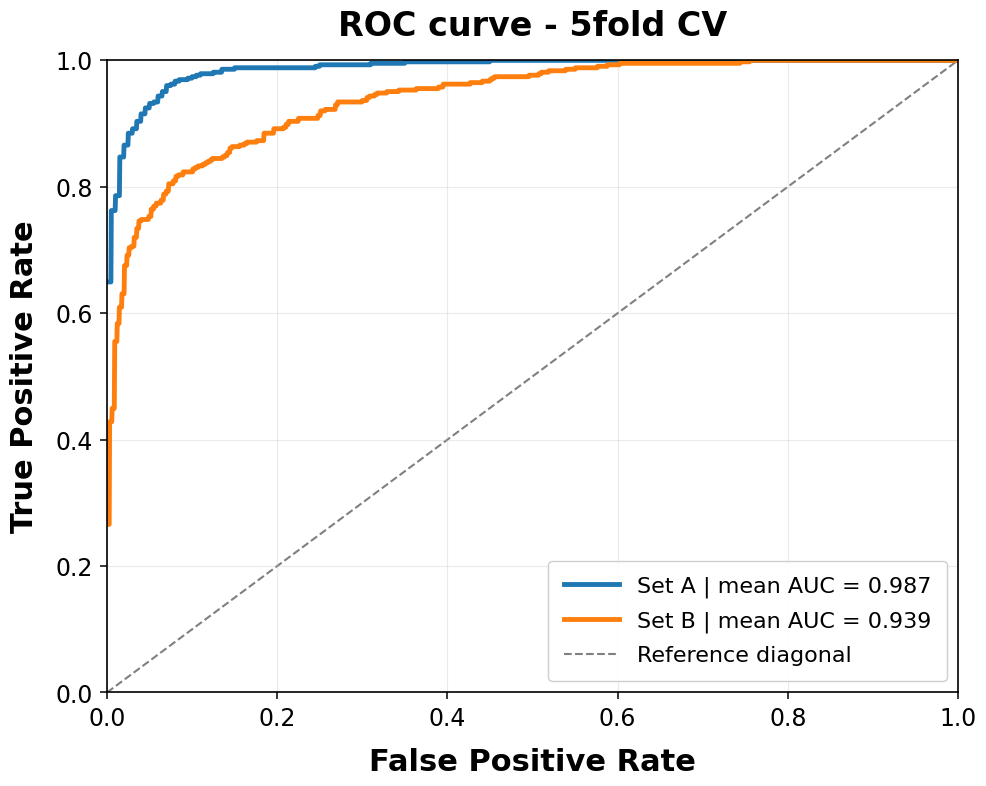

Saved: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github\3-sr_cv.png


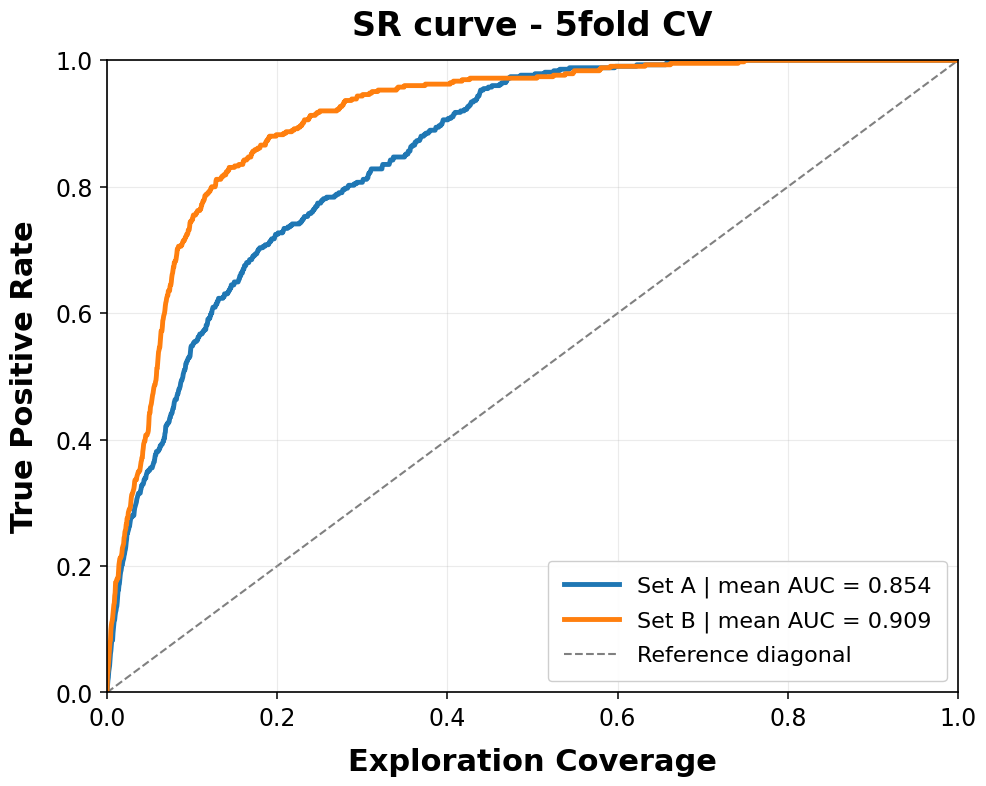

Saved: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github\4-isc_average_cv.png


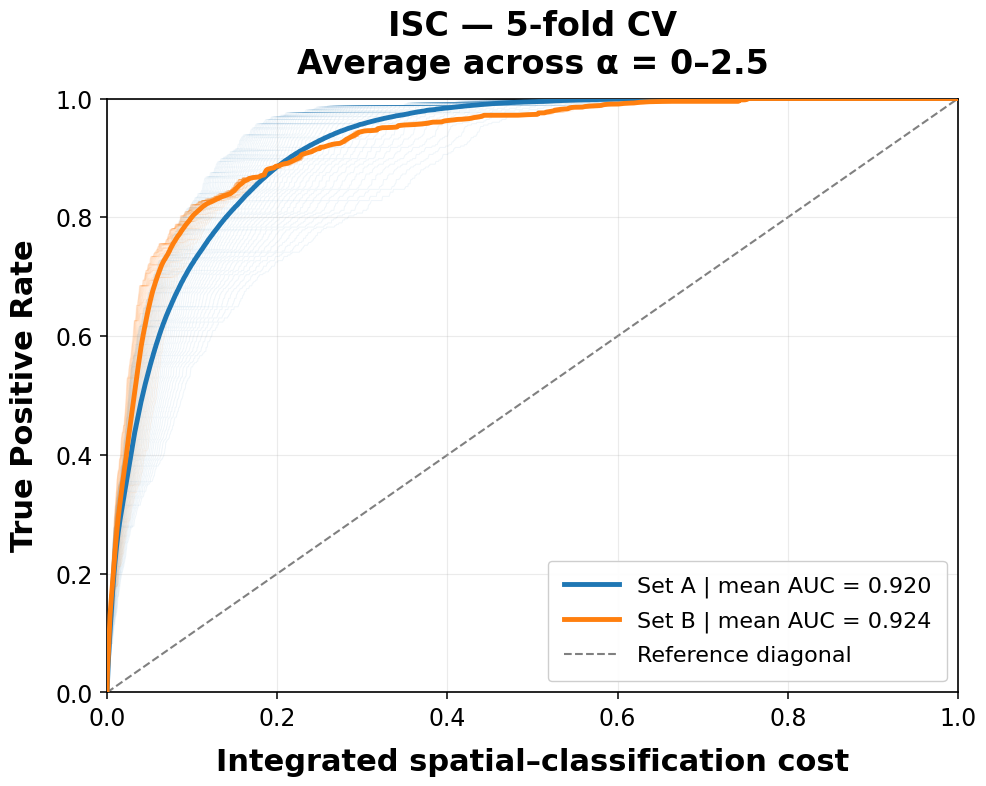

Saved: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github\5-isc_auc_vs_alpha_cv.png


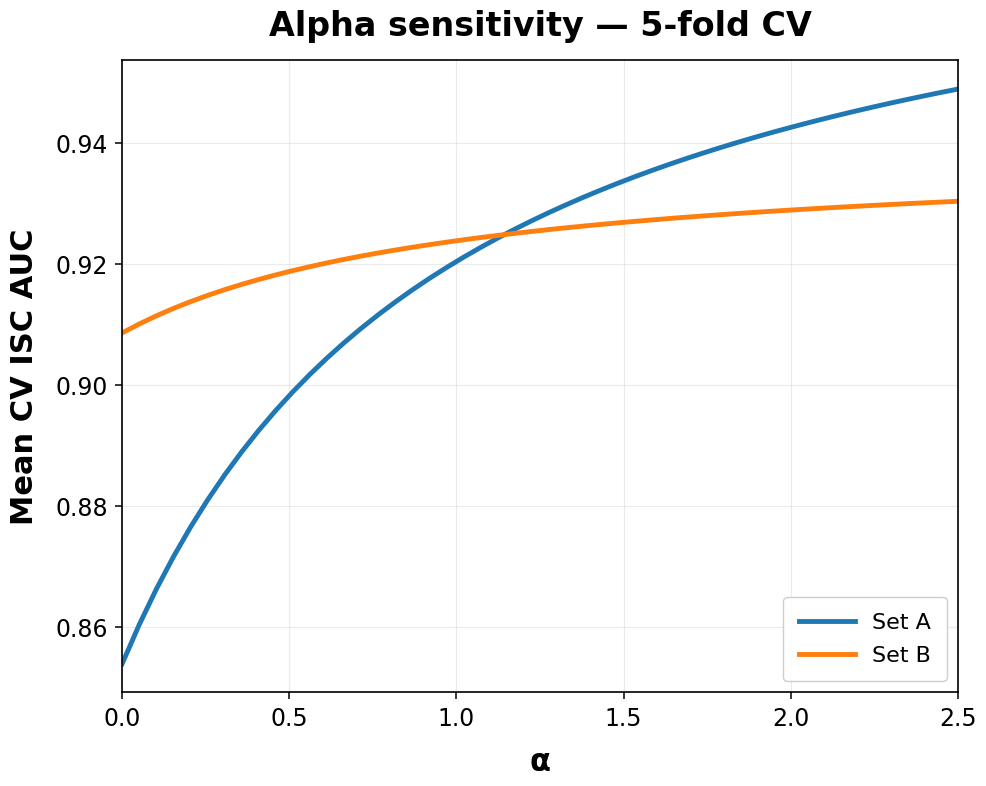


All figures saved in: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github


In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Step 1. Loading 
# ============================================================

RESULTS_DIR = Path("ModelingResults")


PLOT_DIR = Path.cwd()

results_file = RESULTS_DIR / "evaluation_curve_summaries.pkl"

if not results_file.exists():
    raise FileNotFoundError(
        f"{results_file.resolve()} was not found. "
        "Run the modelling code first."
    )

saved = pd.read_pickle(results_file)

curves = saved["curves"]
ALPHA_VALUES = np.asarray(saved["alpha_values"], dtype=float)
PLOT_GRID = np.asarray(saved["plot_grid"], dtype=float)

NEGATIVE_COLS = saved.get("negative_cols", ["SetA", "SetB"])
N_SPLITS = saved.get("n_splits", 5)

STRATEGIES = {
    "SetA": {"name": "Set A", "color": "tab:blue"},
    "SetB": {"name": "Set B", "color": "tab:orange"},
}


for name, style in saved.get("strategies", {}).items():
    STRATEGIES.setdefault(name, dict(style))

missing = [
    name
    for name in NEGATIVE_COLS
    if name not in curves or "cv" not in curves[name]
]

if missing:
    raise ValueError(f"CV results are incomplete for: {missing}")

if ALPHA_VALUES.ndim != 1 or ALPHA_VALUES.size < 2:
    raise ValueError("At least two alpha values are required.")

if not np.isfinite(ALPHA_VALUES).all():
    raise ValueError("Alpha values must be finite.")

if PLOT_GRID.ndim != 1 or PLOT_GRID.size < 2:
    raise ValueError("The plotting grid must contain at least two values.")


# ============================================================
# Step 2. Fonts 
# ============================================================

FIGSIZE = (10, 8)
SAVE_DPI = 600

TITLE_SIZE = 24
AXIS_LABEL_SIZE = 22
TICK_LABEL_SIZE = 17
LEGEND_SIZE = 16

TITLE_WEIGHT = "bold"
AXIS_LABEL_WEIGHT = "bold"

MAIN_LINE_WIDTH = 3.5
REFERENCE_LINE_WIDTH = 1.5
FOLD_LINE_WIDTH = 1.0
ALPHA_LINE_WIDTH = 0.7
AXIS_SPINE_WIDTH = 1.2

LEGEND_LOCATION = "lower right"
LEGEND_HANDLE_LENGTH = 2.5
LEGEND_BORDER_PAD = 0.7
LEGEND_LABEL_SPACING = 0.6

SHOW_SR_FOLD_CURVES = False
SHOW_ALPHA_CURVES = True

FOLD_OPACITY = 0.20
ALPHA_CURVE_OPACITY = 0.07


ROC_TITLE = f"ROC curve - {N_SPLITS}fold CV"
SR_TITLE = f"SR curve - {N_SPLITS}fold CV"

ISC_TITLE = (
    f"ISC — {N_SPLITS}-fold CV\n"
    f"Average across α = "
    f"{ALPHA_VALUES.min():g}–{ALPHA_VALUES.max():g}"
)

ALPHA_TITLE = f"Alpha sensitivity — {N_SPLITS}-fold CV"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})


# ============================================================
# Step 3. Formatting
# ============================================================

def finish_plot(
    fig,
    ax,
    xlabel,
    ylabel,
    title,
    filename,
    reference=True,
):
    """Format, save, display, and close one figure."""

    if reference:
        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="gray",
            linewidth=REFERENCE_LINE_WIDTH,
            label="Reference diagonal",
            zorder=0,
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

    ax.set_xlabel(
        xlabel,
        fontsize=AXIS_LABEL_SIZE,
        fontweight=AXIS_LABEL_WEIGHT,
        labelpad=12,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=AXIS_LABEL_SIZE,
        fontweight=AXIS_LABEL_WEIGHT,
        labelpad=12,
    )

    ax.set_title(
        title,
        fontsize=TITLE_SIZE,
        fontweight=TITLE_WEIGHT,
        pad=18,
    )

    ax.tick_params(
        axis="both",
        labelsize=TICK_LABEL_SIZE,
        width=1.1,
        length=5,
        pad=5,
    )

    for spine in ax.spines.values():
        spine.set_linewidth(AXIS_SPINE_WIDTH)

    ax.set_axisbelow(True)
    ax.grid(alpha=0.25, linewidth=0.8)

    ax.legend(
        loc=LEGEND_LOCATION,
        fontsize=LEGEND_SIZE,
        handlelength=LEGEND_HANDLE_LENGTH,
        borderpad=LEGEND_BORDER_PAD,
        labelspacing=LEGEND_LABEL_SPACING,
        frameon=True,
        facecolor="white",
        framealpha=0.95,
    )

    fig.tight_layout(pad=1.2)

    output_path = PLOT_DIR / filename

    fig.savefig(
        output_path,
        format="png",
        dpi=SAVE_DPI,
        bbox_inches="tight",
        pad_inches=0.15,
        facecolor="white",
        transparent=False,
    )

    print(f"Saved: {output_path.resolve()}")

    plt.show()
    plt.close(fig)


# ============================================================
# Step 4. ROC Curve
# ============================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

for neg_col in NEGATIVE_COLS:
    result = curves[neg_col]["cv"]
    style = STRATEGIES[neg_col]

    ax.plot(
        PLOT_GRID,
        result["roc_plot"],
        color=style["color"],
        linewidth=MAIN_LINE_WIDTH,
        label=(
            f"{style['name']} | "
            f"mean AUC = {result['ROC_AUC']:.3f}"
        ),
    )

finish_plot(
    fig,
    ax,
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=ROC_TITLE,
    filename="2-roc_cv.png",
)


# ============================================================
# Step 5. SR Curve
# ============================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

for neg_col in NEGATIVE_COLS:
    result = curves[neg_col]["cv"]
    style = STRATEGIES[neg_col]

    if SHOW_SR_FOLD_CURVES:
        for fold_curve in result["sr_fold_plots"]:
            ax.plot(
                PLOT_GRID,
                fold_curve,
                color=style["color"],
                linewidth=FOLD_LINE_WIDTH,
                alpha=FOLD_OPACITY,
            )

    ax.plot(
        PLOT_GRID,
        result["sr_plot"],
        color=style["color"],
        linewidth=MAIN_LINE_WIDTH,
        label=(
            f"{style['name']} | "
            f"mean AUC = {result['SR_AUC']:.3f}"
        ),
    )

finish_plot(
    fig,
    ax,
    xlabel="Exploration Coverage",
    ylabel="True Positive Rate",
    title=SR_TITLE,
    filename="3-sr_cv.png",
)


# ============================================================
# Step 6. ISC Curve
# ============================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

for neg_col in NEGATIVE_COLS:
    result = curves[neg_col]["cv"]
    style = STRATEGIES[neg_col]

    if SHOW_ALPHA_CURVES:
        for alpha_curve in result["isc_alpha_plots"]:
            ax.plot(
                PLOT_GRID,
                alpha_curve,
                color=style["color"],
                linewidth=ALPHA_LINE_WIDTH,
                alpha=ALPHA_CURVE_OPACITY,
                zorder=1,
            )

    ax.plot(
        PLOT_GRID,
        result["isc_mean_plot"],
        color=style["color"],
        linewidth=MAIN_LINE_WIDTH,
        zorder=3,
        label=(
            f"{style['name']} | mean AUC = "
            f"{result['ISC_AUC_alpha_mean']:.3f}"
        ),
    )

finish_plot(
    fig,
    ax,
    xlabel="Integrated spatial–classification cost",
    ylabel="True Positive Rate",
    title=ISC_TITLE,
    filename="4-isc_average_cv.png",
)


# ============================================================
# Step 7. Alpha Sensitivity Curve
# ============================================================

fig, ax = plt.subplots(figsize=FIGSIZE)


alpha_order = np.argsort(ALPHA_VALUES)
sorted_alpha = ALPHA_VALUES[alpha_order]

for neg_col in NEGATIVE_COLS:
    result = curves[neg_col]["cv"]
    style = STRATEGIES[neg_col]

    auc_values = np.asarray(
        result["ISC_AUC_values"],
        dtype=float,
    )

    if auc_values.shape != ALPHA_VALUES.shape:
        raise ValueError(
            f"{neg_col}: ISC AUC values must match "
            "the alpha-values array."
        )

    ax.plot(
        sorted_alpha,
        auc_values[alpha_order],
        color=style["color"],
        linewidth=MAIN_LINE_WIDTH,
        label=style["name"],
    )

ax.set_xlim(sorted_alpha.min(), sorted_alpha.max())

finish_plot(
    fig,
    ax,
    xlabel="α",
    ylabel="Mean CV ISC AUC",
    title=ALPHA_TITLE,
    filename="5-isc_auc_vs_alpha_cv.png",
    reference=False,
)

print(f"\nAll figures saved in: {PLOT_DIR.resolve()}")

## **Mapping**

Saved: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github\6-prospectivity_model_A_viridis.png


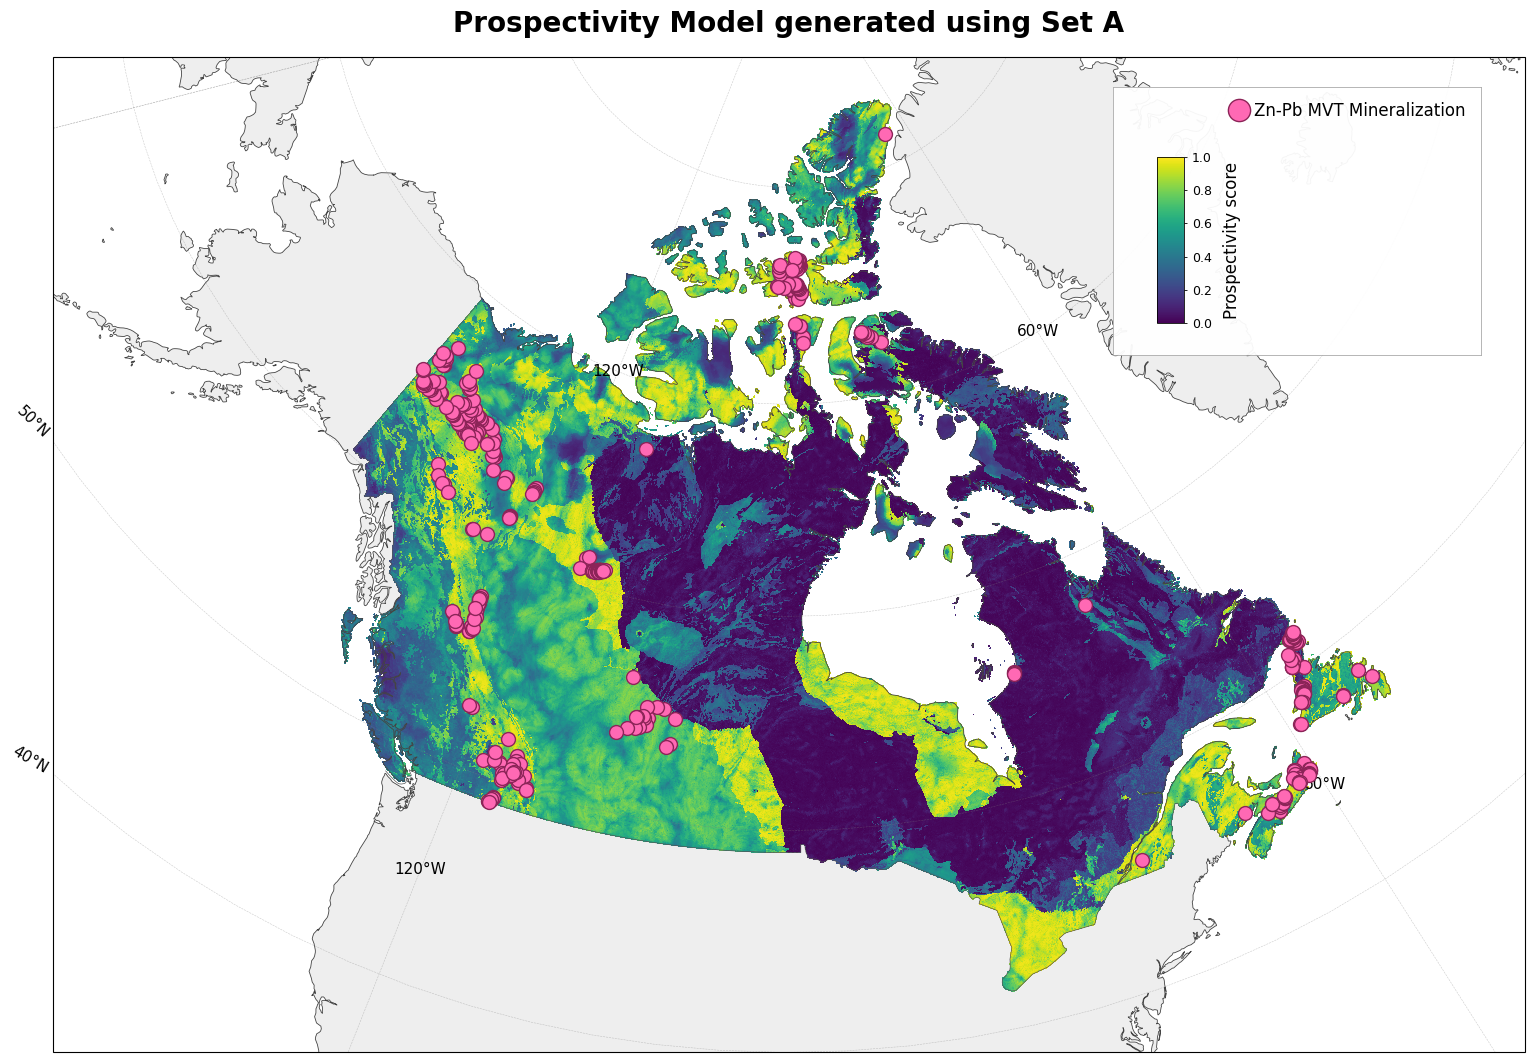

Saved: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github\7-prospectivity_model_B_viridis.png


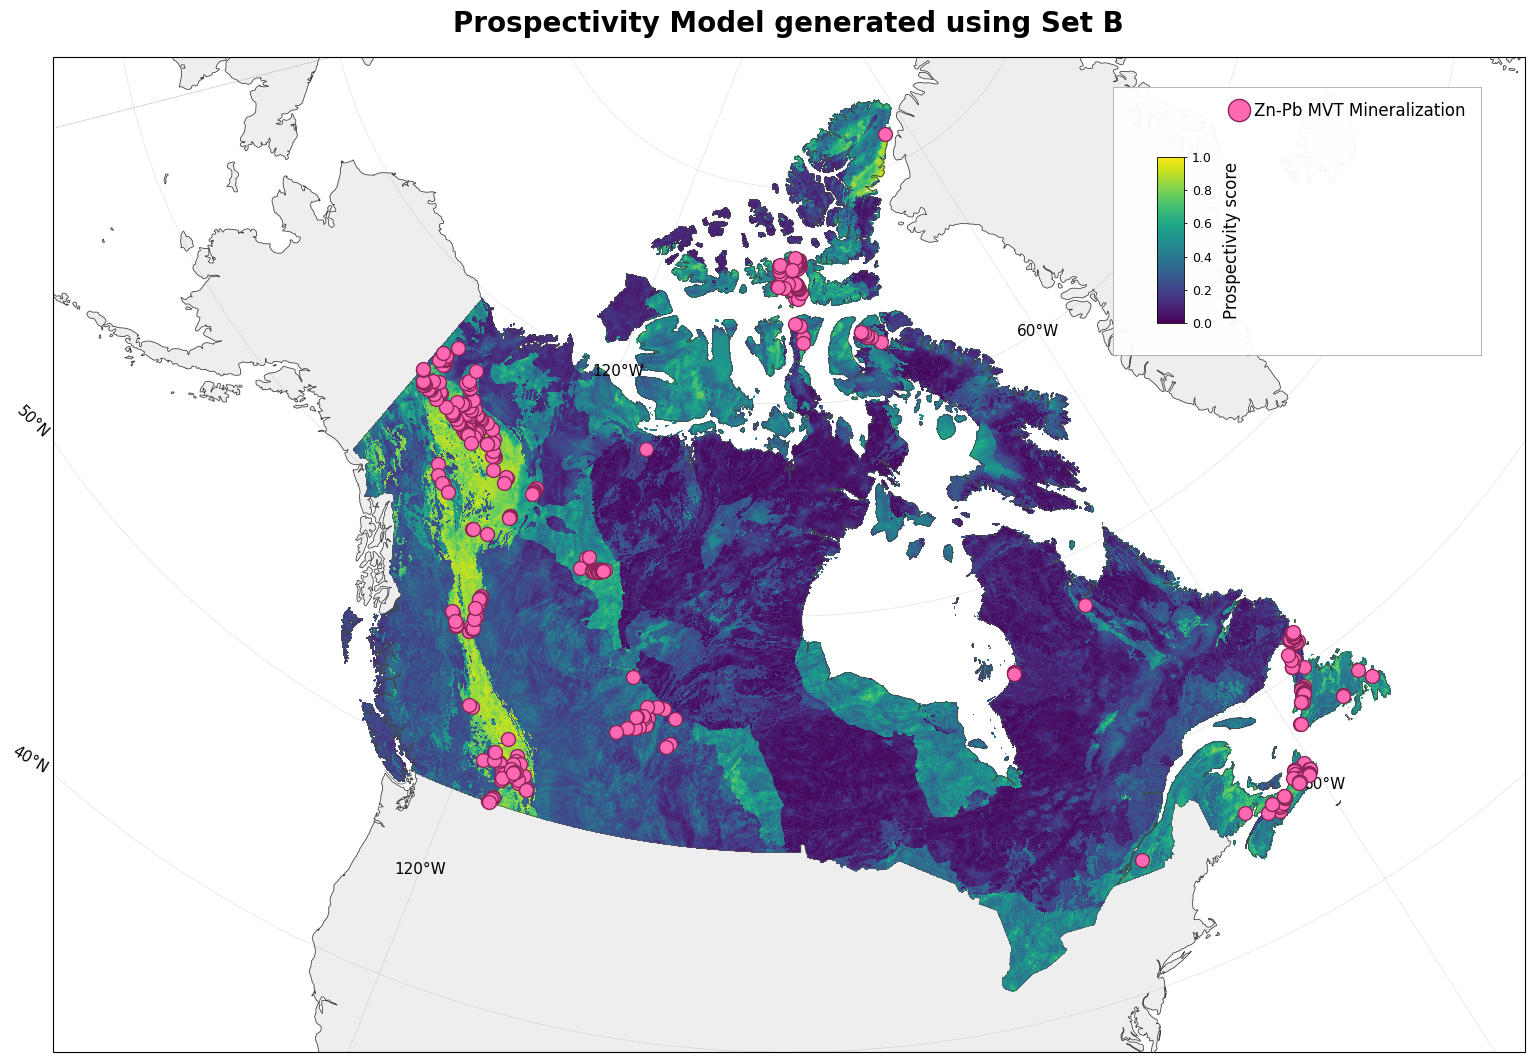


Both maps saved in: C:\Users\mparsasa\OneDrive - NRCan RNCan\Papers2026\Validation of MPM\Revise1\Github


In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

import cartopy.crs as ccrs
import cartopy.feature as cfeature


# ============================================================
# Step 1. General Setting
# ============================================================

MODELS = [
    {
        "column": "prospectivity_model_A",
        "title": "Prospectivity Model generated using Set A",
        "filename": "6-prospectivity_model_A_viridis.png",
    },
    {
        "column": "prospectivity_model_B",
        "title": "Prospectivity Model generated using Set B",
        "filename": "7-prospectivity_model_B_viridis.png",
    },
]


OUTPUT_DIR = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd()
)

FIGSIZE = (16, 12)
SAVE_DPI = 300
POINT_SIZE = 1.0

MAP_EXTENT = [-142, -50, 40, 84]

CMAP = "viridis"
NORM = mcolors.Normalize(vmin=0.0, vmax=1.0, clip=True)

# Target symbols.
TARGET_SIZE = 100
TARGET_FACE_COLOR = "#FF69B4"
TARGET_EDGE_COLOR = "#8C2458"
TARGET_EDGE_WIDTH = 1.0
TARGET_LABEL = "Zn-Pb MVT Mineralization"


LEGEND_BOUNDS = [0.72, 0.70, 0.25, 0.27]

TITLE_SIZE = 20
GRID_LABEL_SIZE = 11
LEGEND_SIZE = 12
COLORBAR_LABEL_SIZE = 12
COLORBAR_TICK_SIZE = 9


# ============================================================
# Step 2. Sanity Check
# ============================================================

required = [
    "longitude",
    "latitude",
    "target",
    *[model["column"] for model in MODELS],
]

missing = [column for column in required if column not in cube.columns]

if missing:
    raise KeyError(f"Missing columns: {missing}")

lon = pd.to_numeric(
    cube["longitude"], errors="coerce"
).to_numpy(dtype=float)

lat = pd.to_numeric(
    cube["latitude"], errors="coerce"
).to_numpy(dtype=float)

target_values = pd.to_numeric(
    cube["target"], errors="coerce"
).to_numpy(dtype=float)

valid_coordinates = (
    np.isfinite(lon)
    & np.isfinite(lat)
    & (lon >= -180)
    & (lon <= 180)
    & (lat >= -90)
    & (lat <= 90)
)

if not valid_coordinates.any():
    raise ValueError("No valid coordinates were found.")

target_mask = (target_values == 1) & valid_coordinates

model_scores = {}

for model in MODELS:
    column = model["column"]

    scores = pd.to_numeric(
        cube[column], errors="coerce"
    ).to_numpy(dtype=float)

    if not np.isfinite(scores).all():
        raise ValueError(
            f"{column} contains missing or invalid scores."
        )

    if ((scores < 0) | (scores > 1)).any():
        raise ValueError(f"{column} contains scores outside 0–1.")

    model_scores[column] = scores


# ============================================================
# Step 3. Project coordinates
# ============================================================

projection = ccrs.LambertConformal(
    central_longitude=-96,
    central_latitude=60,
    standard_parallels=(49, 77),
)

geographic_crs = ccrs.PlateCarree()

map_rows = np.flatnonzero(valid_coordinates)

projected = projection.transform_points(
    geographic_crs,
    lon[map_rows],
    lat[map_rows],
)

valid_projected = np.isfinite(projected[:, :2]).all(axis=1)

map_rows = map_rows[valid_projected]
map_x = projected[valid_projected, 0]
map_y = projected[valid_projected, 1]

if map_rows.size == 0:
    raise ValueError("No coordinates could be projected.")

target_in_map = target_mask[map_rows]

del projected


# ============================================================
# Step 4. Legend symbol
# ============================================================

target_handle = Line2D(
    [],
    [],
    linestyle="none",
    marker="o",
    markerfacecolor=TARGET_FACE_COLOR,
    markeredgecolor=TARGET_EDGE_COLOR,
    markeredgewidth=TARGET_EDGE_WIDTH,
    markersize=16,
    label=TARGET_LABEL,
)


# ============================================================
# Step 5. Create and save Maps
# ============================================================

for model in MODELS:
    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        subplot_kw={"projection": projection},
    )

    fig.subplots_adjust(
        left=0.05,
        right=0.97,
        bottom=0.05,
        top=0.92,
    )

    ax.set_extent(MAP_EXTENT, crs=geographic_crs)
    ax.set_facecolor("white")

    ax.add_feature(
        cfeature.LAND.with_scale("50m"),
        facecolor="#EEEEEE",
        edgecolor="none",
        zorder=0,
    )

    scatter = ax.scatter(
        map_x,
        map_y,
        c=model_scores[model["column"]][map_rows],
        cmap=CMAP,
        norm=NORM,
        s=POINT_SIZE,
        marker="s",
        edgecolors="none",
        linewidths=0,
        rasterized=True,
        transform=projection,
        zorder=1,
    )

    ax.coastlines(
        resolution="50m",
        linewidth=0.6,
        color="#444444",
        zorder=2,
    )

    ax.add_feature(
        cfeature.BORDERS.with_scale("50m"),
        linewidth=0.5,
        edgecolor="#555555",
        zorder=2,
    )

    ax.scatter(
        map_x[target_in_map],
        map_y[target_in_map],
        marker="o",
        s=TARGET_SIZE,
        facecolors=TARGET_FACE_COLOR,
        edgecolors=TARGET_EDGE_COLOR,
        linewidths=TARGET_EDGE_WIDTH,
        transform=projection,
        zorder=4,
    )

    grid = ax.gridlines(
        draw_labels=True,
        linewidth=0.4,
        color="gray",
        alpha=0.4,
        linestyle="--",
        zorder=2,
    )

    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {"size": GRID_LABEL_SIZE}
    grid.ylabel_style = {"size": GRID_LABEL_SIZE}

    ax.set_title(
        model["title"],
        fontsize=TITLE_SIZE,
        fontweight="bold",
        pad=18,
    )



    panel = ax.inset_axes(LEGEND_BOUNDS)
    panel.set_facecolor("white")
    panel.patch.set_alpha(0.95)
    panel.set_xticks([])
    panel.set_yticks([])
    panel.set_zorder(10)

    for spine in panel.spines.values():
        spine.set_edgecolor("#AAAAAA")
        spine.set_linewidth(0.6)

    panel.legend(
        handles=[target_handle],
        loc="upper right",
        fontsize=LEGEND_SIZE,
        frameon=False,
        borderaxespad=0.5,
        handlelength=1.0,
        handletextpad=0.4,
        labelspacing=0.3,
    )

    colorbar_ax = panel.inset_axes(
        [0.12, 0.12, 0.075, 0.62]
    )

    colorbar = fig.colorbar(
        scatter,
        cax=colorbar_ax,
        orientation="vertical",
        ticks=np.linspace(0, 1, 6),
    )

    colorbar.set_label(
        "Prospectivity score",
        fontsize=COLORBAR_LABEL_SIZE,
        labelpad=8,
    )

    colorbar.ax.tick_params(
        labelsize=COLORBAR_TICK_SIZE,
        length=2.5,
        width=0.6,
        pad=3,
    )

    colorbar.outline.set_linewidth(0.6)



    output_path = OUTPUT_DIR / model["filename"]

    fig.savefig(
        output_path,
        format="png",
        dpi=SAVE_DPI,
        bbox_inches="tight",
        pad_inches=0.15,
        facecolor="white",
        transparent=False,
    )

    print(f"Saved: {output_path.resolve()}")

    plt.show()
    plt.close(fig)

print(f"\nBoth maps saved in: {OUTPUT_DIR}")